In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [ ]:
airports_url = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat"
routes_url = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/routes.dat"

airports = pd.read_csv(
    airports_url,
    header=None,
    na_values="\\N"
)

routes = pd.read_csv(
    routes_url,
    header=None,
    na_values="\\N"
)

print("Airports:", airports.shape)
print("Routes:", routes.shape)

Airports: (7698, 14)
Routes: (67663, 9)


In [ ]:
airports.columns = [
    "Airport_ID",
    "Name",
    "City",
    "Country",
    "IATA",
    "ICAO",
    "Latitude",
    "Longitude",
    "Altitude",
    "Timezone",
    "DST",
    "Tz_Database",
    "Type",
    "Source"
]

In [ ]:
routes.columns = [
    "Airline",
    "Airline_ID",
    "Source_Airport",
    "Source_Airport_ID",
    "Destination_Airport",
    "Destination_Airport_ID",
    "Codeshare",
    "Stops",
    "Equipment"
]

In [ ]:
display(airports.head())
display(routes.head())

,Airport_ID,Name,City,Country,IATA,ICAO,Latitude,Longitude,Altitude,Timezone,DST,Tz_Database,Type,Source
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998,5282,10.0,U,Pacific/Port_Moresby,airport,OurAirports
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789001,20,10.0,U,Pacific/Port_Moresby,airport,OurAirports
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005,5388,10.0,U,Pacific/Port_Moresby,airport,OurAirports
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977,239,10.0,U,Pacific/Port_Moresby,airport,OurAirports
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001,146,10.0,U,Pacific/Port_Moresby,airport,OurAirports


,Airline,Airline_ID,Source_Airport,Source_Airport_ID,Destination_Airport,Destination_Airport_ID,Codeshare,Stops,Equipment
0,2B,410.0,AER,2965.0,KZN,2990.0,NaN,0,CR2
1,2B,410.0,ASF,2966.0,KZN,2990.0,NaN,0,CR2
2,2B,410.0,ASF,2966.0,MRV,2962.0,NaN,0,CR2
3,2B,410.0,CEK,2968.0,KZN,2990.0,NaN,0,CR2
4,2B,410.0,CEK,2968.0,OVB,4078.0,NaN,0,CR2


In [ ]:
airports_clean = airports[
    airports["IATA"].notna() &
    airports["Latitude"].notna() &
    airports["Longitude"].notna()
].copy()

print("Clean airports:", len(airports_clean))

Clean airports: 6072


In [ ]:
india_airports = airports_clean[
    airports_clean["Country"] == "India"
].copy()

print("Indian airports:", len(india_airports))

display(
    india_airports[
        ["Name", "City", "IATA", "Latitude", "Longitude"]
    ].head(20)
)

Indian airports: 121


,Name,City,IATA,Latitude,Longitude
2836,Sardar Vallabhbhai Patel International Airport,Ahmedabad,AMD,23.077200,72.634697
2837,Akola Airport,Akola,AKD,20.698999,77.058601
2838,Aurangabad Airport,Aurangabad,IXU,19.862700,75.398102
2839,Chhatrapati Shivaji International Airport,Mumbai,BOM,19.088699,72.867897
2840,Bilaspur Airport,Bilaspur,PAB,21.988400,82.111000
2841,Bhuj Airport,Bhuj,BHJ,23.287800,69.670197
2842,Belgaum Airport,Belgaum,IXG,15.859300,74.618301
2843,Vadodara Airport,Baroda,BDQ,22.336201,73.226303
2844,Raja Bhoj International Airport,Bhopal,BHO,23.287500,77.337402
2845,Bhavnagar Airport,Bhaunagar,BHU,21.752199,72.185204


In [ ]:
india_codes = set(india_airports["IATA"])

#Filter routes

In [ ]:
india_routes = routes[
    routes["Source_Airport"].isin(india_codes) &
    routes["Destination_Airport"].isin(india_codes)
].copy()

print("Indian routes:", len(india_routes))

Indian routes: 1057


In [ ]:
display(
    india_routes[
        ["Source_Airport", "Destination_Airport", "Stops"]
    ].head(20)
)

,Source_Airport,Destination_Airport,Stops
2115,AMD,BLR,0
2116,AMD,BOM,0
2117,AMD,CCU,0
2118,AMD,DEL,0
2119,AMD,GOI,0
2120,AMD,HYD,0
2121,AMD,JAI,0
2122,AMD,MAA,0
2123,AMD,PNQ,0
2124,BBI,BLR,0


#Calculate distance between airports

In [ ]:
from math import radians, sin, cos, sqrt, atan2

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # Earth radius in km

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return R * c

#Create an airport lookup

In [ ]:
airport_info = india_airports.set_index("IATA")[
    ["Name", "City", "Latitude", "Longitude"]
].to_dict("index")

#Calculate route distances

In [ ]:
def get_distance(source, destination):
    s = airport_info[source]
    d = airport_info[destination]

    return haversine(
        s["Latitude"],
        s["Longitude"],
        d["Latitude"],
        d["Longitude"]
    )

In [ ]:
def get_distance(source, destination):
    s = airport_info[source]
    d = airport_info[destination]

    return haversine(
        s["Latitude"],
        s["Longitude"],
        d["Latitude"],
        d["Longitude"]
    )

In [ ]:
print(india_routes.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1057 entries, 2115 to 49554
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Airline                 1057 non-null   object 
 1   Airline_ID              1057 non-null   float64
 2   Source_Airport          1057 non-null   object 
 3   Source_Airport_ID       1006 non-null   float64
 4   Destination_Airport     1057 non-null   object 
 5   Destination_Airport_ID  1006 non-null   float64
 6   Codeshare               294 non-null    object 
 7   Stops                   1057 non-null   int64  
 8   Equipment               1057 non-null   object 
dtypes: float64(3), int64(1), object(5)
memory usage: 82.6+ KB
None


In [ ]:
airport_info = india_airports.set_index("IATA")[
    ["Name", "City", "Latitude", "Longitude"]
].to_dict("index")

print("Airport information created.")
print("Number of airports:", len(airport_info))

Airport information created.
Number of airports: 121


In [ ]:
from math import radians, sin, cos, sqrt, atan2

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2)**2
        + cos(lat1)
        * cos(lat2)
        * sin(dlon / 2)**2
    )

    c = 2 * atan2(
        sqrt(a),
        sqrt(1 - a)
    )

    return R * c


def get_distance(source, destination):

    s = airport_info[source]
    d = airport_info[destination]

    return haversine(
        s["Latitude"],
        s["Longitude"],
        d["Latitude"],
        d["Longitude"]
    )

print("Distance function created.")

Distance function created.


In [ ]:
print(
    "HYD to DEL distance:",
    get_distance("HYD", "DEL")
)

HYD to DEL distance: 1267.683699147248


In [ ]:
india_routes["Distance_km"] = india_routes.apply(
    lambda row: get_distance(
        row["Source_Airport"],
        row["Destination_Airport"]
    ),
    axis=1
)

print("Distance calculation completed.")

Distance calculation completed.


In [ ]:
display(
    india_routes[
        [
            "Source_Airport",
            "Destination_Airport",
            "Distance_km"
        ]
    ].head(20)
)

,Source_Airport,Destination_Airport,Distance_km
2115,AMD,BLR,1221.887619
2116,AMD,BOM,444.160123
2117,AMD,CCU,1619.942522
2118,AMD,DEL,756.520019
2119,AMD,GOI,864.955725
2120,AMD,HYD,887.696750
2121,AMD,JAI,525.502033
2122,AMD,MAA,1374.950962
2123,AMD,PNQ,517.352840
2124,BBI,BLR,1165.681134


In [ ]:
india_routes = india_routes[
    india_routes["Source_Airport"] != india_routes["Destination_Airport"]
].copy()

print("Routes after removing self-loops:", len(india_routes))

Routes after removing self-loops: 1057


In [ ]:
india_routes_unique = (
    india_routes
    .groupby(
        ["Source_Airport", "Destination_Airport"],
        as_index=False
    )["Distance_km"]
    .min()
)

print(
    "Original routes:",
    len(india_routes)
)

print(
    "Unique airport-to-airport routes:",
    len(india_routes_unique)
)

display(india_routes_unique.head(20))

Original routes: 1057
Unique airport-to-airport routes: 381


,Source_Airport,Destination_Airport,Distance_km
0,AGR,BOM,1036.909608
1,AGR,HJR,325.424442
2,AGX,COK,468.039644
3,AJL,CCU,446.243222
4,AJL,GAU,272.609910
5,AJL,IMF,164.921660
6,AMD,BLR,1221.887619
7,AMD,BOM,444.160123
8,AMD,CCU,1619.942522
9,AMD,DEL,756.520019


In [ ]:
G = nx.Graph()
print("Graph created successfully.")

Graph created successfully.


In [ ]:
for _, row in india_airports.iterrows():

    G.add_node(
        row["IATA"],
        name=row["Name"],
        city=row["City"],
        country=row["Country"],
        latitude=row["Latitude"],
        longitude=row["Longitude"]
    )

print("Number of nodes:", G.number_of_nodes())

Number of nodes: 121


In [ ]:
for _, row in india_routes_unique.iterrows():

    source = row["Source_Airport"]
    destination = row["Destination_Airport"]
    distance = row["Distance_km"]

    G.add_edge(
        source,
        destination,
        weight=distance
    )

print("Number of edges:", G.number_of_edges())

Number of edges: 198


In [ ]:
print("========== AIRLINE NETWORK ==========")

print(
    "Number of airports (nodes):",
    G.number_of_nodes()
)

print(
    "Number of routes (edges):",
    G.number_of_edges()
)

print(
    "Is graph connected?:",
    nx.is_connected(G)
)

print(
    "Network density:",
    nx.density(G)
)

========== AIRLINE NETWORK ==========
Number of airports (nodes): 121
Number of routes (edges): 198
Is graph connected?: False
Network density: 0.02727272727272727


In [ ]:
print("HYD node information:")
print(G.nodes["HYD"])

HYD node information:
{'name': 'Rajiv Gandhi International Airport', 'city': 'Hyderabad', 'country': 'India', 'latitude': 17.2313175201, 'longitude': 78.4298553467}


In [ ]:
print("HYD → BOM edge information:")
print(G["HYD"]["BOM"])

HYD → BOM edge information:
{'weight': 622.8388837355327}


In [ ]:
degrees = dict(G.degree())

print("Number of airports:", len(degrees))
print("Maximum degree:", max(degrees.values()))
print("Minimum degree:", min(degrees.values()))

Number of airports: 121
Maximum degree: 45
Minimum degree: 0


In [ ]:
average_degree = sum(degrees.values()) / len(degrees)

print(
    "Average degree:",
    round(average_degree, 2)
)

Average degree: 3.27


In [ ]:
max_degree_airport = max(
    degrees,
    key=degrees.get
)

print(
    "Most connected airport:",
    max_degree_airport
)

print(
    "Number of direct connections:",
    degrees[max_degree_airport]
)

Most connected airport: BOM
Number of direct connections: 45


In [ ]:
degree_df = pd.DataFrame(
    degrees.items(),
    columns=["Airport", "Degree"]
)

degree_df = degree_df.sort_values(
    "Degree",
    ascending=False
)

display(
    degree_df.head(15)
)

,Airport,Degree
3,BOM,45
62,DEL,43
34,CCU,25
78,BLR,24
113,HYD,19
89,MAA,16
22,PNQ,11
101,GAU,10
0,AMD,9
82,COK,9


In [ ]:
degree_centrality = nx.degree_centrality(G)

In [ ]:
degree_centrality_df = pd.DataFrame(
    degree_centrality.items(),
    columns=[
        "Airport",
        "Degree_Centrality"
    ]
)

degree_centrality_df = degree_centrality_df.sort_values(
    "Degree_Centrality",
    ascending=False
)

display(
    degree_centrality_df.head(15)
)

,Airport,Degree_Centrality
3,BOM,0.375000
62,DEL,0.358333
34,CCU,0.208333
78,BLR,0.200000
113,HYD,0.158333
89,MAA,0.133333
22,PNQ,0.091667
101,GAU,0.083333
0,AMD,0.075000
82,COK,0.075000


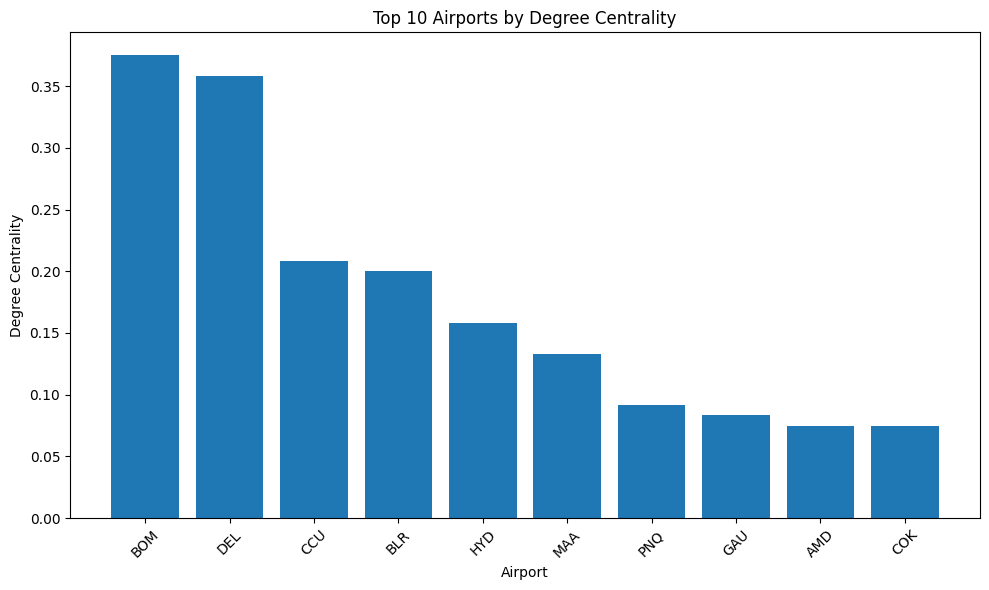

In [ ]:
top10_degree = degree_centrality_df.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top10_degree["Airport"],
    top10_degree["Degree_Centrality"]
)

plt.xlabel("Airport")
plt.ylabel("Degree Centrality")
plt.title(
    "Top 10 Airports by Degree Centrality"
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
closeness = nx.closeness_centrality(
    G,
    distance="weight"
)

In [ ]:
closeness_df = pd.DataFrame(
    closeness.items(),
    columns=[
        "Airport",
        "Closeness_Centrality"
    ]
)

closeness_df = closeness_df.sort_values(
    "Closeness_Centrality",
    ascending=False
)

display(
    closeness_df.head(15)
)

,Airport,Closeness_Centrality
3,BOM,0.000499
22,PNQ,0.000493
113,HYD,0.000480
20,NAG,0.000472
13,IDR,0.000472
25,RPR,0.000468
62,DEL,0.000467
66,JAI,0.000451
8,BHO,0.000445
27,STV,0.000442


In [ ]:
betweenness = nx.betweenness_centrality(
    G,
    weight="weight"
)

In [ ]:
betweenness_df = pd.DataFrame(
    betweenness.items(),
    columns=[
        "Airport",
        "Betweenness_Centrality"
    ]
)

betweenness_df = betweenness_df.sort_values(
    "Betweenness_Centrality",
    ascending=False
)

display(
    betweenness_df.head(15)
)

,Airport,Betweenness_Centrality
3,BOM,0.112045
62,DEL,0.111064
34,CCU,0.068768
78,BLR,0.038655
113,HYD,0.035994
89,MAA,0.025350
55,VNS,0.010364
101,GAU,0.010364
82,COK,0.010364
25,RPR,0.005602


In [ ]:
eigenvector = nx.eigenvector_centrality(
    G,
    max_iter=1000
)

In [ ]:
eigenvector_df = pd.DataFrame(
    eigenvector.items(),
    columns=[
        "Airport",
        "Eigenvector_Centrality"
    ]
)

eigenvector_df = eigenvector_df.sort_values(
    "Eigenvector_Centrality",
    ascending=False
)

display(
    eigenvector_df.head(15)
)

,Airport,Eigenvector_Centrality
3,BOM,0.388795
62,DEL,0.380040
78,BLR,0.289351
34,CCU,0.271621
113,HYD,0.254085
89,MAA,0.227031
22,PNQ,0.203179
0,AMD,0.181408
49,VTZ,0.165146
82,COK,0.152394


In [ ]:
pagerank = nx.pagerank(G)

In [ ]:
pagerank_df = pd.DataFrame(
    pagerank.items(),
    columns=[
        "Airport",
        "PageRank"
    ]
)

pagerank_df = pagerank_df.sort_values(
    "PageRank",
    ascending=False
)

display(
    pagerank_df.head(15)
)

,Airport,PageRank
3,BOM,0.119900
62,DEL,0.113106
34,CCU,0.060168
78,BLR,0.053443
113,HYD,0.036776
89,MAA,0.033960
101,GAU,0.022547
0,AMD,0.021051
22,PNQ,0.020595
82,COK,0.019158


In [ ]:
centrality_df = pd.DataFrame({
    "Airport": list(G.nodes()),

    "Degree_Centrality": [
        degree_centrality.get(n, 0)
        for n in G.nodes()
    ],

    "Closeness_Centrality": [
        closeness.get(n, 0)
        for n in G.nodes()
    ],

    "Betweenness_Centrality": [
        betweenness.get(n, 0)
        for n in G.nodes()
    ],

    "Eigenvector_Centrality": [
        eigenvector.get(n, 0)
        for n in G.nodes()
    ],

    "PageRank": [
        pagerank.get(n, 0)
        for n in G.nodes()
    ]
})

display(
    centrality_df.sort_values(
        "Degree_Centrality",
        ascending=False
    ).head(20)
)

,Airport,Degree_Centrality,Closeness_Centrality,Betweenness_Centrality,Eigenvector_Centrality,PageRank
3,BOM,0.375000,0.000499,0.112045,0.388795,0.119900
62,DEL,0.358333,0.000467,0.111064,0.380040,0.113106
34,CCU,0.208333,0.000398,0.068768,0.271621,0.060168
78,BLR,0.200000,0.000420,0.038655,0.289351,0.053443
113,HYD,0.158333,0.000480,0.035994,0.254085,0.036776
89,MAA,0.133333,0.000402,0.025350,0.227031,0.033960
22,PNQ,0.091667,0.000493,0.000840,0.203179,0.020595
101,GAU,0.083333,0.000327,0.010364,0.125697,0.022547
0,AMD,0.075000,0.000434,0.000000,0.181408,0.021051
82,COK,0.075000,0.000352,0.010364,0.152394,0.019158


In [ ]:
source = "HYD"
destination = "DEL"

shortest_path = nx.shortest_path(
    G,
    source=source,
    target=destination,
    weight="weight"
)

shortest_distance = nx.shortest_path_length(
    G,
    source=source,
    target=destination,
    weight="weight"
)

print("Source:", source)
print("Destination:", destination)

print(
    "\nOptimal Route:"
)

print(
    " → ".join(shortest_path)
)

print(
    f"\nTotal Distance: "
    f"{shortest_distance:.2f} km"
)

Source: HYD
Destination: DEL

Optimal Route:
HYD → DEL

Total Distance: 1267.68 km


In [ ]:
test_routes = [
    ("HYD", "DEL"),
    ("HYD", "BOM"),
    ("HYD", "BLR"),
    ("BOM", "DEL"),
    ("DEL", "MAA"),
    ("BLR", "CCU")
]

for source, destination in test_routes:

    try:

        path = nx.shortest_path(
            G,
            source=source,
            target=destination,
            weight="weight"
        )

        distance = nx.shortest_path_length(
            G,
            source=source,
            target=destination,
            weight="weight"
        )

        print(
            f"\n{source} → {destination}"
        )

        print(
            "Optimal Route:",
            " → ".join(path)
        )

        print(
            f"Distance: {distance:.2f} km"
        )

    except nx.NetworkXNoPath:

        print(
            f"\nNo route found: "
            f"{source} → {destination}"
        )


HYD → DEL
Optimal Route: HYD → DEL
Distance: 1267.68 km

HYD → BOM
Optimal Route: HYD → BOM
Distance: 622.84 km

HYD → BLR
Optimal Route: HYD → BLR
Distance: 455.16 km

BOM → DEL
Optimal Route: BOM → DEL
Distance: 1138.23 km

DEL → MAA
Optimal Route: DEL → MAA
Distance: 1760.86 km

BLR → CCU
Optimal Route: BLR → CCU
Distance: 1546.84 km


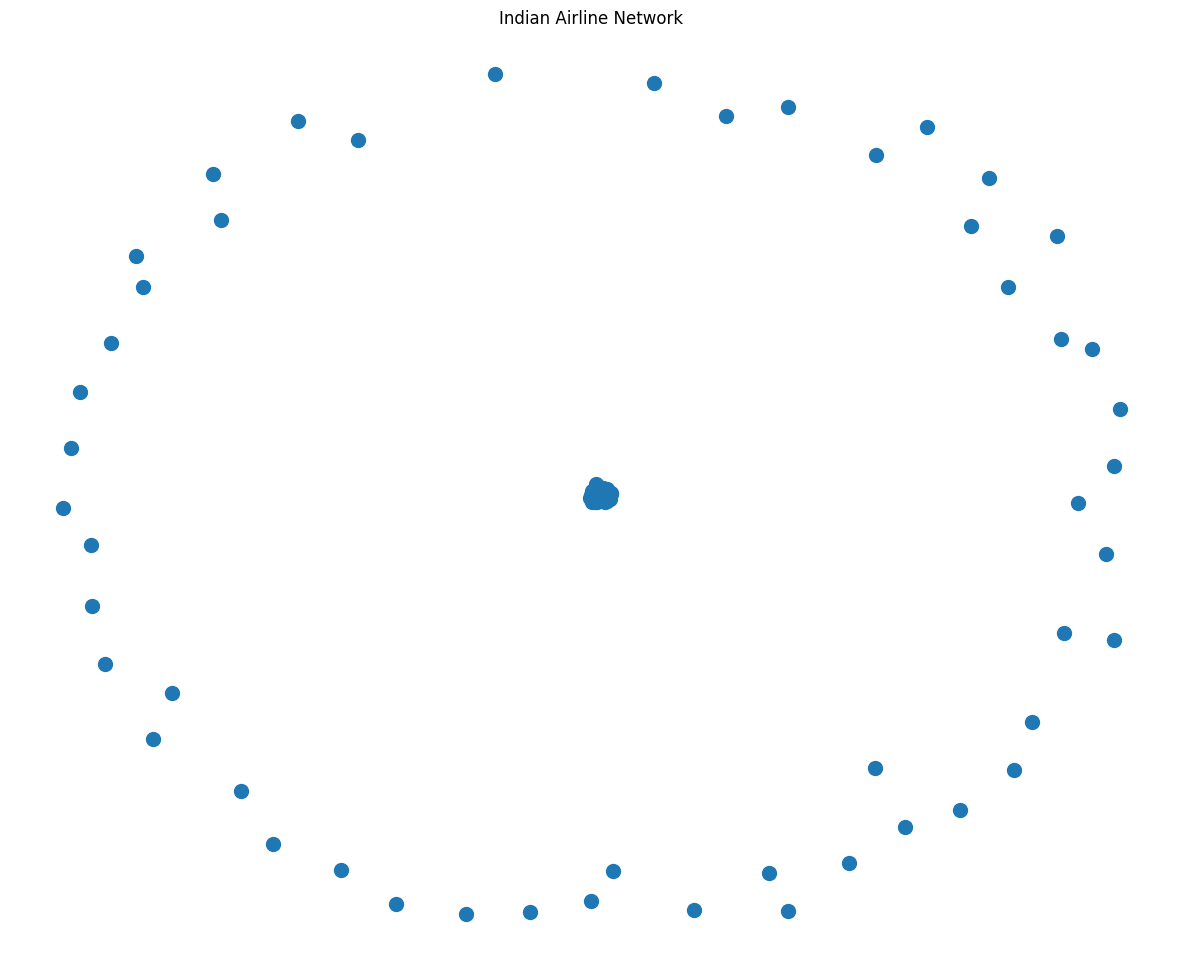

In [ ]:
plt.figure(figsize=(15, 12))

pos = nx.spring_layout(
    G,
    seed=42
)

nx.draw_networkx(
    G,
    pos,
    with_labels=False,
    node_size=100,
    width=0.5
)

plt.title(
    "Indian Airline Network"
)

plt.axis("off")
plt.show()

In [ ]:
from networkx.algorithms.community import (
    greedy_modularity_communities
)

communities = list(
    greedy_modularity_communities(G)
)

print(
    "Number of communities:",
    len(communities)
)

Number of communities: 55


In [ ]:
for i, community in enumerate(
    communities,
    start=1
):

    print(
        f"\nCommunity {i} "
        f"({len(community)} airports):"
    )

    print(
        sorted(community)
    )


Community 1 (31 airports):
['ATQ', 'BDQ', 'BHJ', 'BHU', 'BOM', 'DED', 'DEL', 'DHM', 'DIU', 'GOP', 'GWL', 'HBX', 'IXC', 'IXD', 'IXJ', 'IXL', 'IXR', 'IXU', 'JDH', 'JGA', 'JLR', 'KNU', 'KUU', 'LKO', 'LUH', 'PAT', 'PBD', 'RAJ', 'STV', 'SXR', 'UDR']

Community 2 (20 airports):
['AGX', 'AMD', 'BLR', 'CCJ', 'CJB', 'COK', 'GOI', 'HYD', 'IXE', 'IXG', 'IXM', 'JAI', 'MAA', 'MYQ', 'PNQ', 'RJA', 'TIR', 'TRV', 'TRZ', 'VGA']

Community 3 (13 airports):
['AJL', 'BBI', 'CCU', 'DIB', 'DMU', 'GAU', 'IMF', 'IXA', 'IXB', 'IXS', 'IXZ', 'SHL', 'VTZ']

Community 4 (4 airports):
['BHO', 'IDR', 'NAG', 'RPR']

Community 5 (3 airports):
['AGR', 'HJR', 'VNS']

Community 6 (1 airports):
['AKD']

Community 7 (1 airports):
['PAB']

Community 8 (1 airports):
['NMB']

Community 9 (1 airports):
['GUX']

Community 10 (1 airports):
['IXY']

Community 11 (1 airports):
['KLH']

Community 12 (1 airports):
['IXK']

Community 13 (1 airports):
['ISK']

Community 14 (1 airports):
['SSE']

Community 15 (1 airports):
['IXV']

Com

In [ ]:
centrality_df.to_csv(
    "airport_centrality_analysis.csv",
    index=False
)

degree_df.to_csv(
    "airport_degree_analysis.csv",
    index=False
)

india_routes_unique.to_csv(
    "indian_airline_network_routes.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [ ]:
print("=" * 70)
print("GRAPH-BASED AIRLINE NETWORK ANALYSIS")
print("=" * 70)

print("\nNETWORK OVERVIEW")
print("-" * 70)
print("Number of Airports:", G.number_of_nodes())
print("Number of Routes:", G.number_of_edges())
print("Network Density:", round(nx.density(G), 4))
print("Average Degree:", round(average_degree, 2))
print("Number of Communities:", len(communities))

print("\nTOP AIRPORTS")
print("-" * 70)

print(
    "Degree Centrality:",
    degree_centrality_df.iloc[0]["Airport"]
)

print(
    "Closeness Centrality:",
    closeness_df.iloc[0]["Airport"]
)

print(
    "Betweenness Centrality:",
    betweenness_df.iloc[0]["Airport"]
)

print(
    "Eigenvector Centrality:",
    eigenvector_df.iloc[0]["Airport"]
)

print(
    "PageRank:",
    pagerank_df.iloc[0]["Airport"]
)

print("\nSAMPLE OPTIMAL ROUTE")
print("-" * 70)

source = "HYD"
destination = "DEL"

path = nx.shortest_path(
    G,
    source=source,
    target=destination,
    weight="weight"
)

distance = nx.shortest_path_length(
    G,
    source=source,
    target=destination,
    weight="weight"
)

print("Source:", source)
print("Destination:", destination)
print("Optimal Route:", " → ".join(path))
print("Distance:", round(distance, 2), "km")

print("\n" + "=" * 70)
print("PROJECT COMPLETED")
print("=" * 70)

GRAPH-BASED AIRLINE NETWORK ANALYSIS

NETWORK OVERVIEW
----------------------------------------------------------------------
Number of Airports: 121
Number of Routes: 198
Network Density: 0.0273
Average Degree: 3.27
Number of Communities: 55

TOP AIRPORTS
----------------------------------------------------------------------
Degree Centrality: BOM
Closeness Centrality: BOM
Betweenness Centrality: BOM
Eigenvector Centrality: BOM
PageRank: BOM

SAMPLE OPTIMAL ROUTE
----------------------------------------------------------------------
Source: HYD
Destination: DEL
Optimal Route: HYD → DEL
Distance: 1267.68 km

PROJECT COMPLETED


In [ ]:
top_airports = pd.DataFrame({
    "Metric": [
        "Degree Centrality",
        "Closeness Centrality",
        "Betweenness Centrality",
        "Eigenvector Centrality",
        "PageRank"
    ],

    "Top Airport": [
        degree_centrality_df.iloc[0]["Airport"],
        closeness_df.iloc[0]["Airport"],
        betweenness_df.iloc[0]["Airport"],
        eigenvector_df.iloc[0]["Airport"],
        pagerank_df.iloc[0]["Airport"]
    ]
})

display(top_airports)

,Metric,Top Airport
0,Degree Centrality,BOM
1,Closeness Centrality,BOM
2,Betweenness Centrality,BOM
3,Eigenvector Centrality,BOM
4,PageRank,BOM
